## <b> <span style='color:#e61227'>|</span> Traffic Signs Detection Using YOLOv8 </b> 

![](https://learnopencv.com/wp-content/uploads/2023/01/evolution-of-yolo-models-1024x576.png)

## <b>1 <span style='color:#e61227'>|</span> 引言</b> 

<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227'>1.1 |</span></b> 目标检测</b></p>
</div>

**计算机视觉**是人工智能的一个领域，致力于让计算机能够理解和解析视觉信息。在目标检测任务中，一种流行且强大的技术是 **YOLO**（You Only Look Once，意为“你只需看一次”）。

YOLO 的目标是在图像或视频流中**实时识别并定位物体**。与依赖复杂流程和多次扫描的传统方法不同，YOLO 采用了一种全新思路：将目标检测视为一个**端到端的回归问题**。

该算法将输入图像划分为一个网格，并为每个网格单元预测其中物体的边界框（bounding box）和类别概率。它能够**同时预测类别标签及其对应的边界框**，因此效率极高、速度极快。YOLO 以其出色的实时性能著称，能够以惊人的速度处理图像和视频。

通过利用**深度卷积神经网络**，YOLO 能够学习识别各种类型的物体，并在图像中精确定位它们的位置。它可**同时检测多个不同类别的物体**，因此特别适用于对**实时处理能力**和**高检测精度**要求严苛的应用场景，例如**自动驾驶**、**视频监控**和**机器人技术**。

<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227'>1.2 |</span></b> YOLOv8</b></p>
</div>

**YOLOv8** 是由 **Ultralytics** 开发的 YOLO 系列人工智能模型的最新版本，在处理**图像分类**、**目标检测**和**图像分割**等任务中表现出色。**YOLOv8 模型**兼具速度快、精度高和易用性强的优点，非常适合各类目标检测与图像分割应用场景。这些模型可在大规模数据集上进行训练，并支持在多种硬件平台上运行，从 **CPU** 到 **GPU** 均可高效部署。

YOLOv8 的**目标检测模型**没有后缀，是 YOLOv8 的默认模型（例如 **yolov8n.pt**），并在 COCO 数据集上进行了预训练。更多详细信息，请参阅 [目标检测官方文档](https://docs.ultralytics.com/tasks/detect/)。

<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227'>1.3 |</span></b> 研究目标</b></p>
</div>

利用 **YOLOv8** 实现**标志检测**（Sign Detection）在众多实际应用场景中具有巨大的潜力。例如，该技术可显著提升**交通管理系统**的能力，高效检测并识别各类交通标志。通过使车辆能够准确理解并响应道路标志所传递的信息，这项技术在提高道路安全方面发挥着至关重要的作用。此外，基于 YOLOv8 的标志检测还可用于城市规划与基础设施建设，通过分析不同区域中标志的存在情况与完好状态，为决策提供数据支持。

通过本项目，我旨在充分发挥 YOLOv8 的强大性能，开发一套**可靠的标志检测解决方案**，以期在各类依赖精准、高效标志识别的领域中带来切实改进。

## <b>2 <span style='color:#e61227'>|</span> Install And Import Essential Libreries</b> 


In [1]:
# Install Essential Libraries
!pip install ultralytics

In [2]:
# Import Essential Libraries
import os
import random
import pandas as pd
from PIL import Image
import cv2
from ultralytics import YOLO
from IPython.display import Video
import numpy as np  
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='darkgrid')
import pathlib
import glob
from tqdm.notebook import trange, tqdm
import warnings
warnings.filterwarnings('ignore')

In [3]:
# Configure the visual appearance of Seaborn plots
sns.set(rc={'axes.facecolor': '#eae8fa'}, style='darkgrid')

## <b>3 <span style='color:#e61227'>|</span> Dataset</b> 

<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227'>3.1 |</span></b> 显示训练图片 </b></p>
</div>

***3.1.1. Show Some Images From TrainSet***

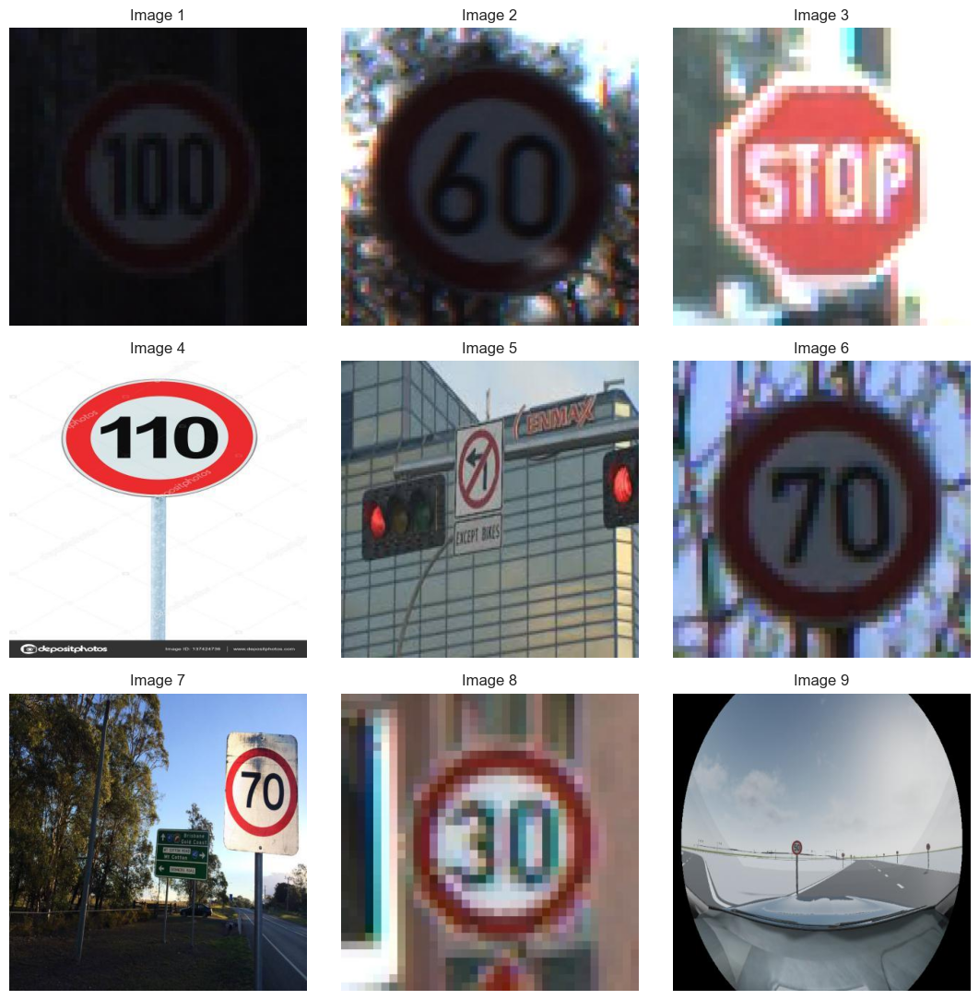

In [4]:
Image_dir = 'cardetection/car/train/images'

num_samples = 9
image_files = os.listdir(Image_dir)

# Randomly select num_samples images
rand_images = random.sample(image_files, num_samples)

fig, axes = plt.subplots(3, 3, figsize=(11, 11))

for i in range(num_samples):
    image = rand_images[i]
    ax = axes[i // 3, i % 3]
    ax.imshow(plt.imread(os.path.join(Image_dir, image)))
    ax.set_title(f'Image {i+1}')
    ax.axis('off')

plt.tight_layout()
plt.show()

***3.1.2. Get Shape Of An Image For Using In Training Step***

In [5]:
# Get the size of the image
image = cv2.imread("cardetection/car/train/images/00000_00000_00012_png.rf.23f94508dba03ef2f8bd187da2ec9c26.jpg")
h, w, c = image.shape
print(f"The image has dimensions {w}x{h} and {c} channels.")

The image has dimensions 416x416 and 3 channels.


## <b>4 <span style='color:#e61227'>|</span> Try Pre-trained YOLOv8 For Detect Traffic Signs  </b>


image 1/1 D:\Pycharm\\Traffic Signs Detection Using YOLOv8\cardetection\car\train\images\FisheyeCamera_1_00228_png.rf.e7c43ee9b922f7b2327b8a00ccf46a4c.jpg: 640x640 (no detections), 161.7ms
Speed: 6.9ms preprocess, 161.7ms inference, 2.3ms postprocess per image at shape (1, 3, 640, 640)


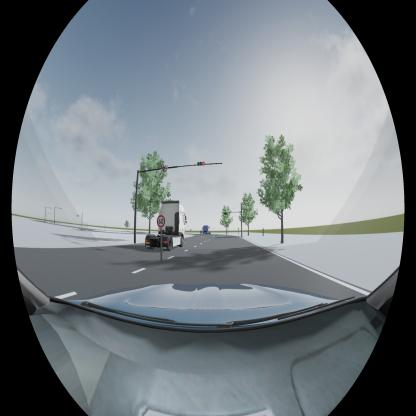

In [6]:
# Use a pretrained YOLOv8n model
model = YOLO("yolov8n.pt") 

# Use the model to detect object
image = "cardetection/car/train/images/FisheyeCamera_1_00228_png.rf.e7c43ee9b922f7b2327b8a00ccf46a4c.jpg"
result_predict = model.predict(source = image, imgsz=(640))

# show results
plot = result_predict[0].plot()
plot = cv2.cvtColor(plot, cv2.COLOR_BGR2RGB)
display(Image.fromarray(plot))

## <b>5 <span style='color:#e61227'>|</span> 基于 YOLOv8 的交通标志检测模型</b>

<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227'>5.1 |</span></b> 使用自定义交通标志数据集进行模型训练</b></p>
</div>

***平均精度均值**（Mean Average Precision, mAP）是用于评估目标检测算法在图像中识别和定位物体效果的核心指标。它综合考虑了不同类别下的**精确率**（Precision）与**召回率**（Recall）。具体而言，mAP 通过计算每个类别的平均精度（AP），再取其平均值，从而对算法的整体性能给出全面评估。

如果在最后一个训练周期（epoch）后得到的 mAP 结果不理想，可通过以下几种方式优化模型性能：

- **增加训练轮数**（epochs）：延长训练过程有助于模型学习更多特征模式，从而可能提升性能。可在训练命令中为 `--epochs` 参数指定更大的值。
- **调整超参数**：尝试修改不同参数以观察其对结果的影响，关键参数包括：
  - **批大小**（Batch Size）：批大小会影响模型的收敛速度与泛化能力。可通过调整 `--batch-size` 参数寻找最优值。
  - **初始学习率**（lr0）：初始学习率决定了训练初期的更新步长。调节 `--lr0` 可控制模型的学习速度。
  - **最终学习率比例**（lrf）：该参数定义训练结束时学习率相对于初始值的比例。调整 `--lrf` 有助于设计更优的学习率调度策略。
  - **更换优化器**（Optimizer）：优化器负责根据梯度更新模型参数。Ultralytics YOLOv8 支持多种优化器，如 SGD、Adam 和 RMSprop。通过修改 `--optimizer` 参数尝试不同优化器，有时可显著改善收敛效果。

有关恢复中断训练及其他高级训练选项的详细信息，请参阅 Ultralytics YOLOv8 官方文档。

为优化模型性能，我们系统性地开展了多组实验，测试了不同参数组合与优化器的效果。在训练阶段，我探索了多种 **epochs、batch size、初始学习率**（lr0）的组合。具体实验设置如下：

- **训练轮数**（Epochs）：***10***、***50***、***100***
- **批大小**（Batch Sizes）：***8***、***16***、***32***、***64***
- **初始学习率**（lr0）：***0.001***、***0.0003***、***0.0001***
- **Dropout 率**：***0.15***、***0.25***

此外，我们还分别使用 **Adam**、**SGD** 和 **auto**（自动选择）三种优化器评估模型性能，旨在分析不同优化策略对模型收敛速度与最终效果的影响。

经过严谨的实验与训练，我们很高兴在此展示研究成果。YOLOv8 模型的性能通过多项指标进行评估，其中核心指标即为**平均精度均值**（mAP）。

***5.1.1. Training Step***

In [7]:
!pip install --upgrade ultralytics ray


                                              0.0/26.7 MB ? eta -:--:--
                                              0.0/26.7 MB ? eta -:--:--
                                              0.0/26.7 MB ? eta -:--:--
                                              0.0/26.7 MB ? eta -:--:--
                                              0.0/26.7 MB ? eta -:--:--
                                              0.0/26.7 MB ? eta -:--:--
                                              0.0/26.7 MB ? eta -:--:--
                                              0.0/26.7 MB 1.4 MB/s eta 0:00:20
                                              0.0/26.7 MB 1.4 MB/s eta 0:00:20
                                              0.0/26.7 MB 1.4 MB/s eta 0:00:20
                                              0.0/26.7 MB 1.4 MB/s eta 0:00:20
                                              0.0/26.7 MB 1.4 MB/s eta 0:00:20
                                             0.1/26.7 MB 182.2 kB/s eta 0:02:27
                     

In [8]:
# Build from YAML and transfer weights
Final_model = YOLO('yolov8n.pt')  

# Training The Final Model
Result_Final_model = Final_model.train(data="cardetection/car/data.yaml",epochs = 30, batch = -1, optimizer = 'auto')


Ultralytics 8.3.228  Python-3.11.9 torch-2.9.1+cpu CPU (12th Gen Intel Core i7-12700H)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=cardetection/car/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose

***5.1.2. Validation Step***

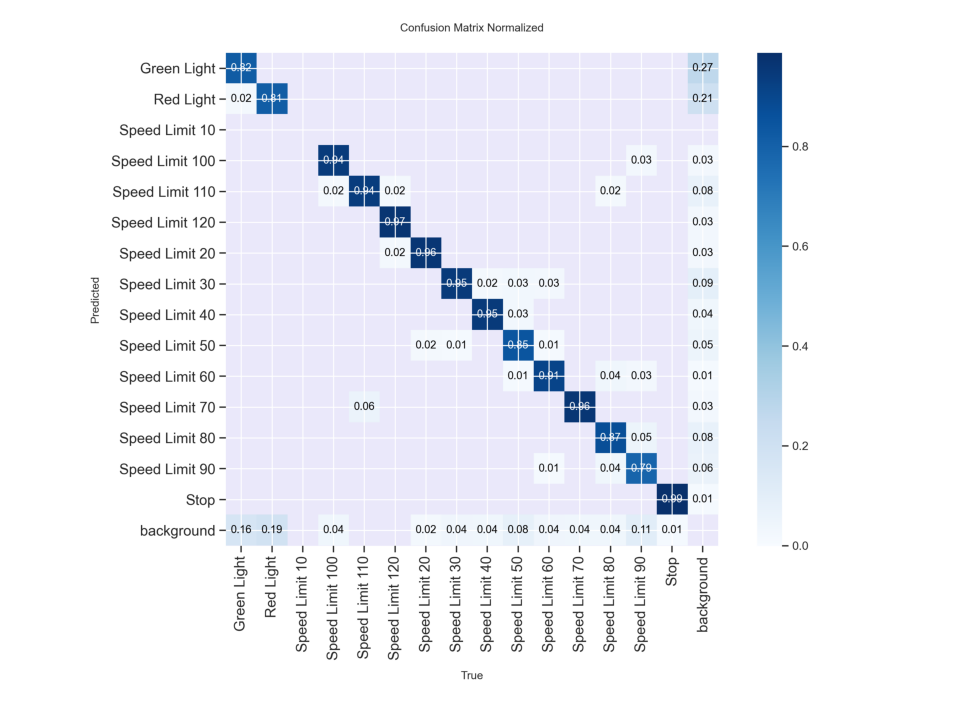

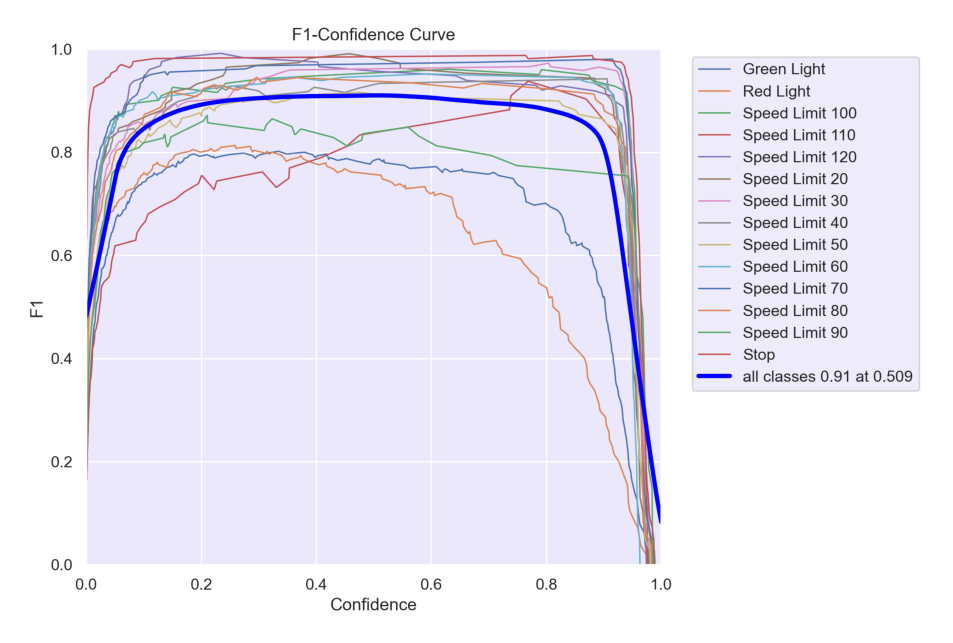

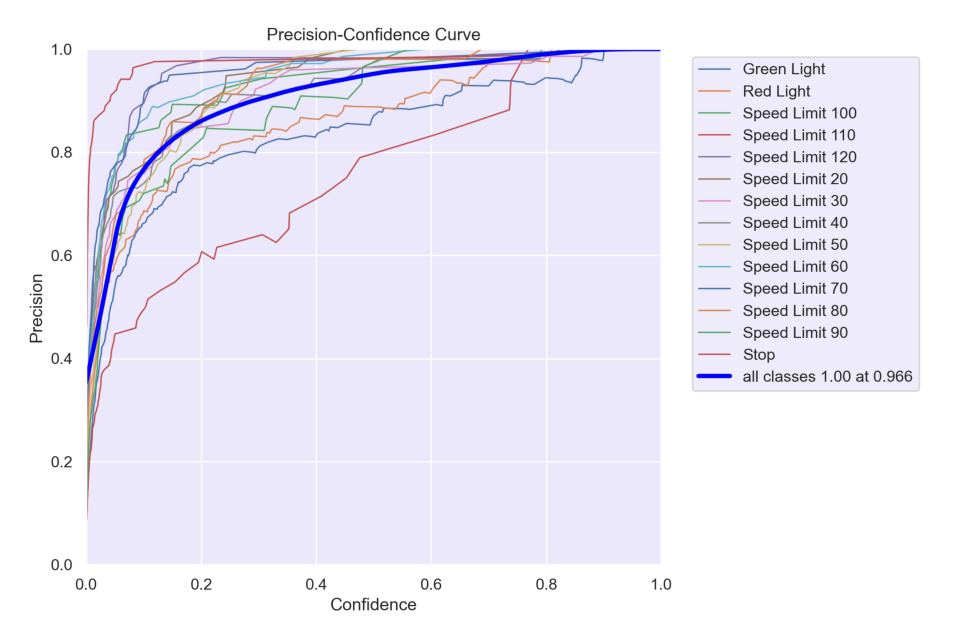

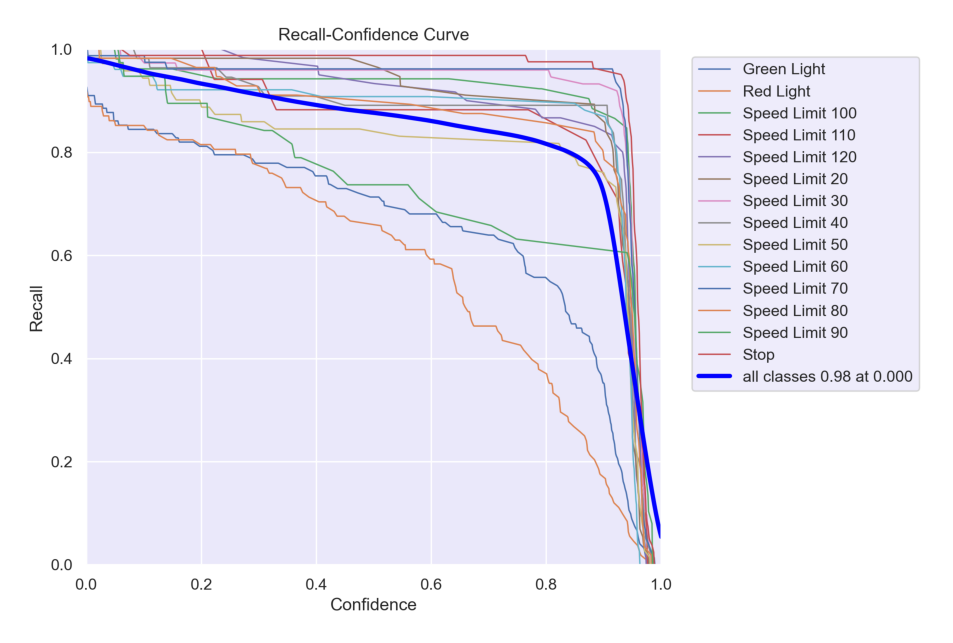

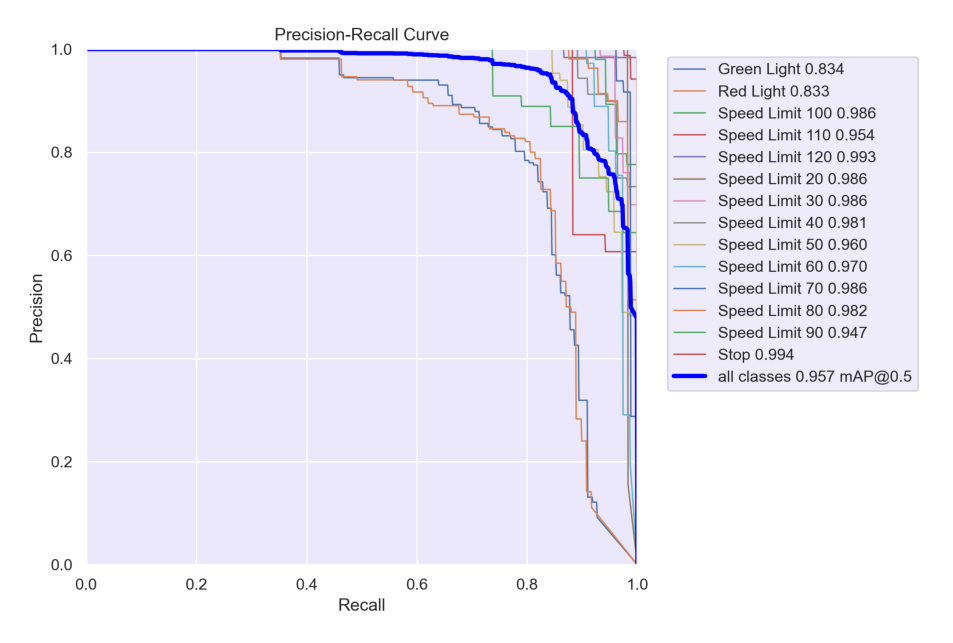

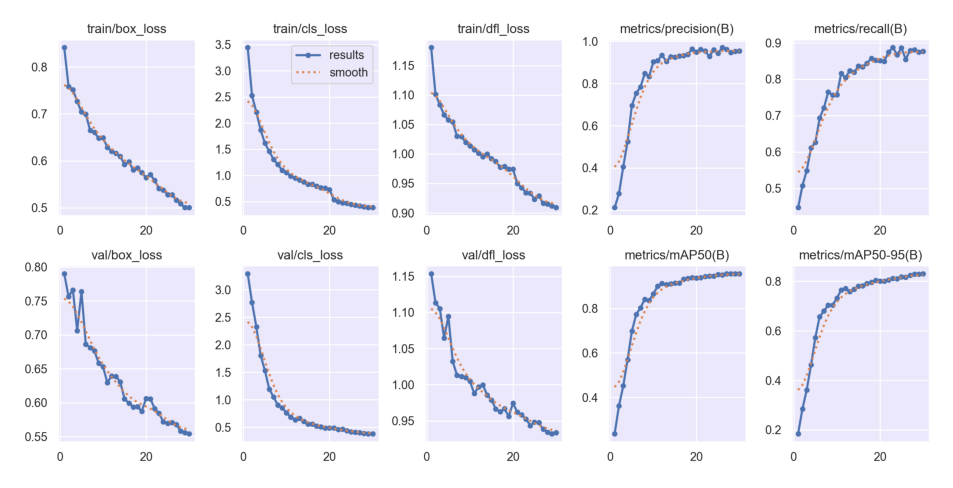

In [11]:
import os
import cv2
import matplotlib.pyplot as plt

def display_images(post_training_files_path, image_files):

    for image_file in image_files:
        image_path = os.path.join(post_training_files_path, image_file)
        img = cv2.imread(image_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        plt.figure(figsize=(10, 10), dpi=120)
        plt.imshow(img)
        plt.axis('off')
        plt.show()

# List of image files to display
image_files = [
    'confusion_matrix_normalized.png',
    'BoxF1_curve.png',
    'BoxP_curve.png',
    'BoxR_curve.png',
    'BoxPR_curve.png',
    'results.png'
]

# Path to the directory containing the images
post_training_files_path = 'runs/detect/train'

# Display the images
display_images(post_training_files_path, image_files)


In [12]:
Result_Final_model = pd.read_csv('runs/detect/train/results.csv')
Result_Final_model.tail(10)

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
20,21,69733.5,0.57087,0.53485,0.95009,0.96154,0.84872,0.93923,0.80073,0.60589,0.48564,0.96209,0.000179,0.000179,0.000179
21,22,70353.5,0.55814,0.49924,0.94288,0.95418,0.87440,0.94461,0.80539,0.59137,0.46226,0.95833,0.000161,0.000161,0.000161
22,23,70960.8,0.54126,0.47583,0.93444,0.92844,0.88674,0.94690,0.81125,0.58466,0.46375,0.95271,0.000144,0.000144,0.000144
23,24,71580.8,0.53799,0.46426,0.93385,0.95963,0.86749,0.94566,0.80947,0.57199,0.43638,0.94360,0.000127,0.000127,0.000127
24,25,72209.8,0.52813,0.44620,0.92334,0.94398,0.88580,0.95380,0.81844,0.56962,0.41681,0.94833,0.000109,0.000109,0.000109
25,26,72813.7,0.52799,0.42783,0.92869,0.97035,0.85468,0.95157,0.81631,0.57101,0.40840,0.94746,0.000092,0.000092,0.000092
26,27,73428.0,0.51636,0.41394,0.91624,0.96156,0.87896,0.95627,0.82363,0.56805,0.39974,0.93847,0.000075,0.000075,0.000075
27,28,74049.5,0.50905,0.39967,0.91533,0.94664,0.88115,0.95624,0.82875,0.55852,0.38533,0.93441,0.000057,0.000057,0.000057
28,29,74657.2,0.50037,0.38827,0.91190,0.95319,0.87432,0.95676,0.82936,0.55573,0.38308,0.93218,0.000040,0.000040,0.000040
29,30,75275.7,0.50069,0.38168,0.90893,0.95524,0.87654,0.95662,0.83052,0.55430,0.38155,0.93387,0.000023,0.000023,0.000023


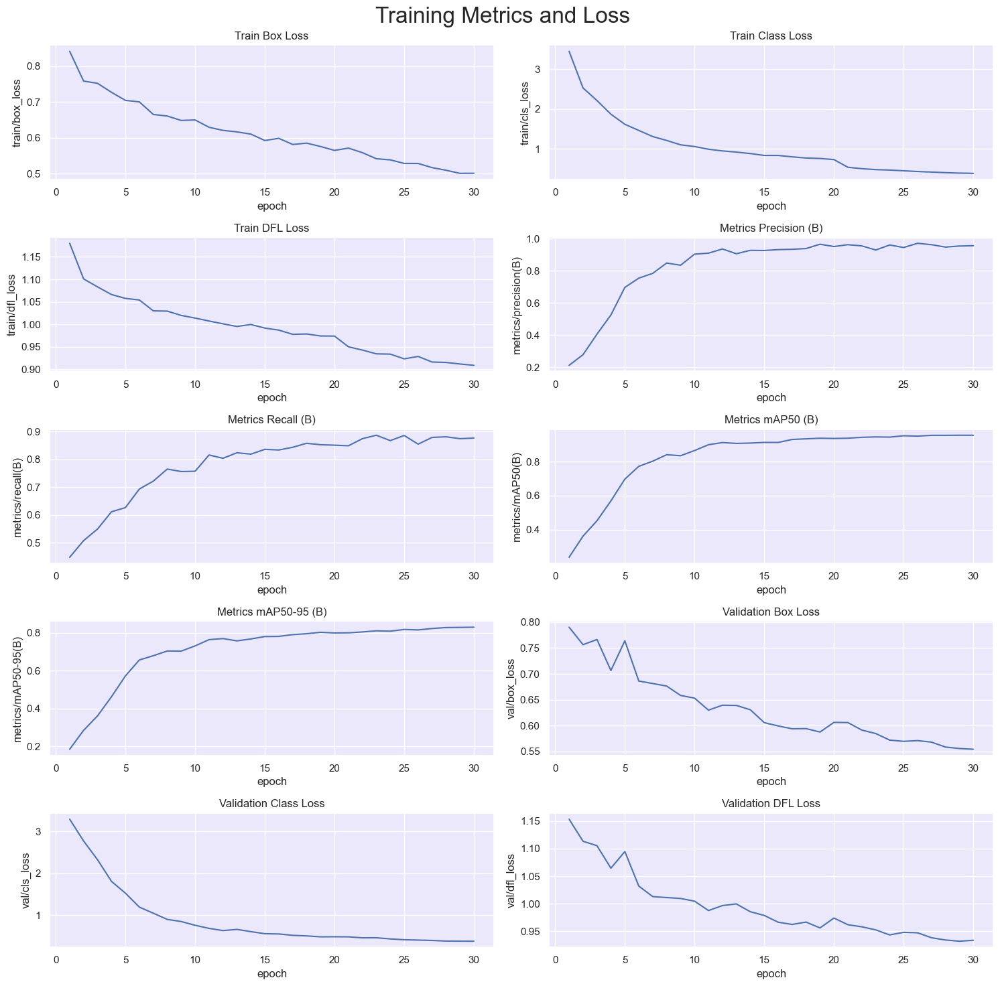

In [13]:
# Read the results.csv file as a pandas dataframe
Result_Final_model.columns = Result_Final_model.columns.str.strip()

# Create subplots
fig, axs = plt.subplots(nrows=5, ncols=2, figsize=(15, 15))

# Plot the columns using seaborn
sns.lineplot(x='epoch', y='train/box_loss', data=Result_Final_model, ax=axs[0,0])
sns.lineplot(x='epoch', y='train/cls_loss', data=Result_Final_model, ax=axs[0,1])
sns.lineplot(x='epoch', y='train/dfl_loss', data=Result_Final_model, ax=axs[1,0])
sns.lineplot(x='epoch', y='metrics/precision(B)', data=Result_Final_model, ax=axs[1,1])
sns.lineplot(x='epoch', y='metrics/recall(B)', data=Result_Final_model, ax=axs[2,0])
sns.lineplot(x='epoch', y='metrics/mAP50(B)', data=Result_Final_model, ax=axs[2,1])
sns.lineplot(x='epoch', y='metrics/mAP50-95(B)', data=Result_Final_model, ax=axs[3,0])
sns.lineplot(x='epoch', y='val/box_loss', data=Result_Final_model, ax=axs[3,1])
sns.lineplot(x='epoch', y='val/cls_loss', data=Result_Final_model, ax=axs[4,0])
sns.lineplot(x='epoch', y='val/dfl_loss', data=Result_Final_model, ax=axs[4,1])

# Set titles and axis labels for each subplot
axs[0,0].set(title='Train Box Loss')
axs[0,1].set(title='Train Class Loss')
axs[1,0].set(title='Train DFL Loss')
axs[1,1].set(title='Metrics Precision (B)')
axs[2,0].set(title='Metrics Recall (B)')
axs[2,1].set(title='Metrics mAP50 (B)')
axs[3,0].set(title='Metrics mAP50-95 (B)')
axs[3,1].set(title='Validation Box Loss')
axs[4,0].set(title='Validation Class Loss')
axs[4,1].set(title='Validation DFL Loss')


plt.suptitle('Training Metrics and Loss', fontsize=24)
plt.subplots_adjust(top=0.8)
plt.tight_layout()
plt.show()

<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227''>5.2 |</span></b> Validation of the Model By TestSet </b></p>
</div>

In [14]:
# Loading the best performing model
Valid_model = YOLO('runs/detect/train/weights/best.pt')

# Evaluating the model on the validset
metrics = Valid_model.val(split = 'val')

# final results 
print("precision(B): ", metrics.results_dict["metrics/precision(B)"])
print("metrics/recall(B): ", metrics.results_dict["metrics/recall(B)"])
print("metrics/mAP50(B): ", metrics.results_dict["metrics/mAP50(B)"])
print("metrics/mAP50-95(B): ", metrics.results_dict["metrics/mAP50-95(B)"])

Ultralytics 8.3.228  Python-3.11.9 torch-2.9.1+cpu CPU (12th Gen Intel Core i7-12700H)
Model summary (fused): 72 layers, 3,008,573 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 189.576.0 MB/s, size: 21.3 KB)
val: Scanning D:\Pycharm\医学图像处理实验课\Traffic Signs Detection Using YOLOv8\cardetection\car\valid\labels.cache... 801 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 801/801 400.5Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 51/51 1.3it/s 40.6s0.8ss
                   all        801        944      0.955      0.877      0.957      0.831
           Green Light         87        122      0.878      0.713      0.834      0.507
             Red Light         74        108      0.888      0.658      0.833      0.529
       Speed Limit 100         52         52      0.967      0.942      0.986      0.888
       Speed Limit 110         17         17      0.801      0.882      0.

<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227''>5.3 |</span></b> Making Predictions On Test Images </b></p>
</div>


0: 640x640 1 Speed Limit 30, 58.1ms
Speed: 22.8ms preprocess, 58.1ms inference, 2.8ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Speed Limit 30, 51.5ms
Speed: 2.2ms preprocess, 51.5ms inference, 0.5ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Speed Limit 70, 48.8ms
Speed: 2.5ms preprocess, 48.8ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Stop, 45.7ms
Speed: 2.1ms preprocess, 45.7ms inference, 0.5ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 2 Speed Limit 70s, 50.5ms
Speed: 2.6ms preprocess, 50.5ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 2 Green Lights, 50.9ms
Speed: 3.3ms preprocess, 50.9ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Red Light, 50.5ms
Speed: 3.9ms preprocess, 50.5ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Green Light, 52.2ms
Speed: 2.3ms preprocess, 52.2ms inference, 

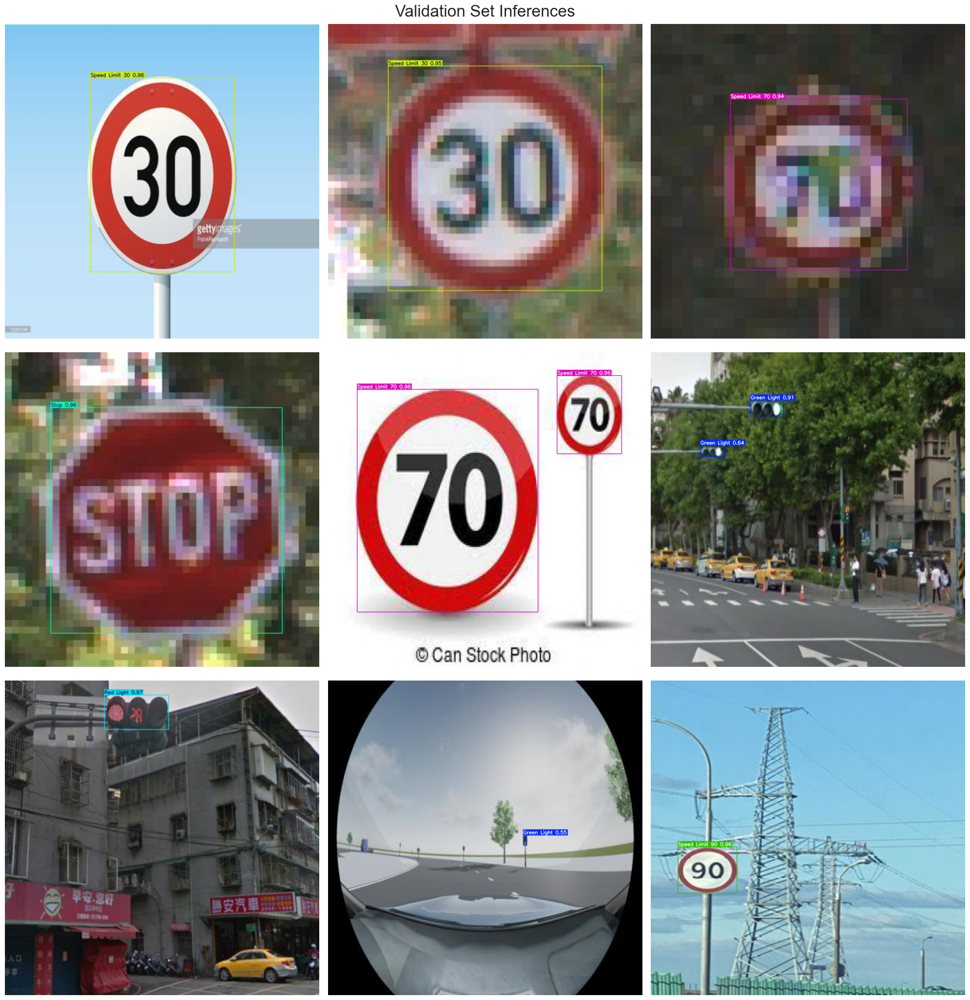

In [15]:
# Normalization function
def normalize_image(image):
    return image / 255.0

# Image resizing function
def resize_image(image, size=(640, 640)):
    return cv2.resize(image, size)

# Path to validation images
dataset_path = 'cardetection/car'  # Place your dataset path here
valid_images_path = os.path.join(dataset_path, 'test', 'images')

# List of all jpg images in the directory
image_files = [file for file in os.listdir(valid_images_path) if file.endswith('.jpg')]

# Check if there are images in the directory
if len(image_files) > 0:
    # Select 9 images at equal intervals
    num_images = len(image_files)
    step_size = max(1, num_images // 9)  # Ensure the interval is at least 1
    selected_images = [image_files[i] for i in range(0, num_images, step_size)]

    # Prepare subplots
    fig, axes = plt.subplots(3, 3, figsize=(20, 21))
    fig.suptitle('Validation Set Inferences', fontsize=24)

    for i, ax in enumerate(axes.flatten()):
        if i < len(selected_images):
            image_path = os.path.join(valid_images_path, selected_images[i])
            
            # Load image
            image = cv2.imread(image_path)
            
            # Check if the image is loaded correctly
            if image is not None:
                # Resize image
                resized_image = resize_image(image, size=(640, 640))
                # Normalize image
                normalized_image = normalize_image(resized_image)
                
                # Convert the normalized image to uint8 data type
                normalized_image_uint8 = (normalized_image * 255).astype(np.uint8)
                
                # Predict with the model
                results = Valid_model.predict(source=normalized_image_uint8, imgsz=640, conf=0.5)
                
                # Plot image with labels
                annotated_image = results[0].plot(line_width=1)
                annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
                ax.imshow(annotated_image_rgb)
            else:
                print(f"Failed to load image {image_path}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()


## <b>6 <span style='color:#e61227'>|</span> Try Pre-trained YOLOv8 For Detect Traffic Signs From Video  </b>
<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227'>6.1 |</span></b> Show Original Video Before Detect </b></p>
</div>

**Tip: Due to the substantial volume of the video generated from the image dataset, I have to utilize only a truncated segment of the original video for this project.**

In [22]:
# # Convert mp4
# !ffmpeg -y -loglevel panic -i /kaggle/input/cardetection/video.mp4 output.mp4## <b>6 <span style='color:#e61227'>|</span> Export The Final Model Of Detect Traffic Signs </b>

# **Tip:** The ultimate goal of training a model is to deploy it for real-world applications. Export mode in Ultralytics YOLOv8 offers a versatile range of options for exporting your trained model to different formats, making it deployable across various platforms and devices.

# # Display the video
# Video("output.mp4", width=960)

In [33]:
!conda install -c conda-forge ffmpeg -y

Channels:
 - conda-forge
 - defaults
Platform: win-64
Solving environment: ...working... done

## Package Plan ##

  environment location: C:\Users\XiaoXiongtao\anaconda3

  added / updated specs:
    - ffmpeg


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    aom-3.7.1                  |       h63175ca_0         1.9 MB  conda-forge
    ca-certificates-2025.11.12 |       h4c7d964_0         149 KB  conda-forge
    certifi-2025.11.12         |     pyhd8ed1ab_0         153 KB  conda-forge
    conda-23.11.0              |  py311h1ea47a8_1         1.2 MB  conda-forge
    dav1d-1.2.1                |       hcfcfb64_0         604 KB  conda-forge
    expat-2.7.1                |       hac47afa_0         229 KB  conda-forge
    ffmpeg-6.1.0               | gpl_h0859920_103         9.2 MB  conda-forge
    font-ttf-dejavu-sans-mono-2.37|       hab24e00_0         388 KB  conda-forge
    font-ttf-inco

In [34]:
# Convert mp4
!ffmpeg -y -loglevel panic -i cardetection/video.mp4 output.mp4

# Display the video
Video("output.mp4", width=960, embed=True)

## <b>6 <span style='color:#e61227'>|</span> Export The Final Model Of Detect Traffic Signs </b>

**Tip:** The ultimate goal of training a model is to deploy it for real-world applications. Export mode in Ultralytics YOLOv8 offers a versatile range of options for exporting your trained model to different formats, making it deployable across various platforms and devices.

In [36]:
# Use the model to detect signs
Valid_model.predict(source="cardetection/video.mp4", show=True,save = True)


WARNING 
inference results will accumulate in RAM unless `stream=True` is passed, causing potential out-of-memory
errors for large sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/508) D:\Pycharm\\Traffic Signs Detection Using YOLOv8\cardetection\video.mp4: 640x640 1 Stop, 272.6ms
video 1/1 (frame 2/508) D:\Pycharm\\Traffic Signs Detection Using YOLOv8\cardetection\video.mp4: 640x640 1 Stop, 208.5ms
video 1/1 (frame 3/508) D:\Pycharm\\Traffic Signs Detection Using YOLOv8\cardetection\video.mp4: 640x640 1 Stop, 205.7ms
video 1/1 (frame 4/508) D:\Pycharm\\Traffic Signs Detection Using YOLOv8\cardetection\video.mp4:

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 keypoints: None
 masks: None
 names: {0: 'Green Light', 1: 'Red Light', 2: 'Speed Limit 10', 3: 'Speed Limit 100', 4: 'Speed Limit 110', 5: 'Speed Limit 120', 6: 'Speed Limit 20', 7: 'Speed Limit 30', 8: 'Speed Limit 40', 9: 'Speed Limit 50', 10: 'Speed Limit 60', 11: 'Speed Limit 70', 12: 'Speed Limit 80', 13: 'Speed Limit 90', 14: 'Stop'}
 obb: None
 orig_img: array([[[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        ...,
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
     

In [37]:
# show result
# Convert format
!ffmpeg -y -loglevel panic -i runs/detect/predict/video.avi result_out.mp4

# Display the video 
Video("result_out.mp4", width=960)

## <b>7 <span style='color:#e61227'>|</span> Save Model  </b>
<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227'></span></b> </b></p>
</div>

In [41]:
!pip install onnx onnxruntime onnxslim --upgrade

In [43]:
# Export the model
Valid_model.export(format='onnx')

Ultralytics 8.3.228  Python-3.11.9 torch-2.9.1+cpu CPU (12th Gen Intel Core i7-12700H)

PyTorch: starting from 'runs\detect\train\weights\best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 19, 8400) (6.0 MB)

ONNX: starting export with onnx 1.19.1 opset 22...
ONNX: slimming with onnxslim 0.1.74...
ONNX: export success  3.9s, saved as 'runs\detect\train\weights\best.onnx' (11.7 MB)

Export complete (4.3s)
Results saved to D:\Pycharm\\Traffic Signs Detection Using YOLOv8\runs\detect\train\weights
Predict:         yolo predict task=detect model=runs\detect\train\weights\best.onnx imgsz=640  
Validate:        yolo val task=detect model=runs\detect\train\weights\best.onnx imgsz=640 data=cardetection/car/data.yaml  
Visualize:       https://netron.app


'runs\\detect\\train\\weights\\best.onnx'